# Is one product's clock offset from another's?

**Two processings of the same probe can disagree on *when* a particle was seen by tens of seconds, and nothing in either file says so.** Missed, the offset biases every in-cloud comparison: here a 47 s offset turns a true B/A ratio of 0.90 into 0.73 and drops the in-cloud 1 Hz correlation from 0.98 to 0.56. A lag scan of the two 1 Hz concentration series, and of each against an independent aircraft-time cloud flag, finds the offset and names the late clock in one pass over the time series.

**What you get**

- the offset and which product carries it, confirmed leg by leg;
- a rule: a lag of 10 s or less, compare cloud-leg composites; above 10 s, shift and re-check;
- window scans that tell a fixed offset from a mid-flight step, and a check that catches a flag left on the wrong clock.

> **Every number in this notebook is synthetic**, drawn from a fixed-seed random-number generator in section 1; no data file is read.

| Best lag | What it means | What to do |
|---|---|---|
| ≤ 10 s | edge jitter, buffering, a time-stamp convention | compare **cloud-leg composites** (one mean per leg), never second by second |
| > 10 s | a systematic timing issue | **flag it and correct it** (shift one product's time axis) before any ratio is quoted |

Sign convention: a lag of `+L` means `b[t + L]` matches `a[t]`, so B's clock runs `L` seconds late and is corrected by subtracting `L` from B's timestamps.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [03_comparing_processing_chains_in_db](../7_analysis_and_outputs/03_comparing_processing_chains_in_db.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )


This cell builds the made-up flight used in the rest of the notebook: a two-hour record with twelve cloud legs, a cloud flag from another instrument, and two products from the same probe, one of them with its clock running late by a known number of seconds.

In [2]:
"""1. A synthetic flight: cloud legs, a reference cloud flag, and two products of one probe."""
import numpy as np

rng = np.random.default_rng(20261002)
N_SECONDS = 7200                       # a two-hour flight at 1 Hz

# Truth on aircraft time: twelve cloud legs of 60-400 s, each with its own mean concentration.
# The independent reference is another instrument's cloud flag, on aircraft time, its leg edges
# jittered by up to 2 s.
truth = np.zeros(N_SECONDS)
in_cloud = np.zeros(N_SECONDS, dtype=bool)
flag = np.zeros(N_SECONDS, dtype=bool)
starts = np.arange(200, N_SECONDS - 600, 560)[:12]
for start in starts:
    length = int(rng.integers(60, 400))
    leg_mean = rng.lognormal(np.log(50.0), 0.6)                  # per litre
    truth[start:start + length] = leg_mean * rng.lognormal(0.0, 0.35, length)
    in_cloud[start:start + length] = True
    j1, j2 = rng.integers(-2, 3, size=2)
    flag[start + j1:start + length + j2] = True

# Product A: on aircraft time, Poisson counting noise.  Product B: a different processing that
# keeps 90 % of A's particles, with its clock running OFFSET seconds late.
SAMPLE_VOLUME_L = 2.0                                            # litres sampled per second
OFFSET = 47
a = rng.poisson(truth * SAMPLE_VOLUME_L) / SAMPLE_VOLUME_L
b_aircraft_time = rng.poisson(0.9 * truth * SAMPLE_VOLUME_L) / SAMPLE_VOLUME_L
b = np.roll(b_aircraft_time, OFFSET)                             # b[t + 47] is what A saw at t
b[:OFFSET] = 0.0

print(f"{in_cloud.sum()} in-cloud seconds in {len(starts)} legs; injected offset of B: {OFFSET} s")

3007 in-cloud seconds in 12 legs; injected offset of B: 47 s


The same file in xarray, which most earth-science tools read: the two products written as netCDF files, then opened with `xarray`.

<xarray.Dataset> Size: 115kB
Dimensions:              (time: 7200)
Coordinates:
  * time                 (time) int64 58kB 0 1 2 3 4 ... 7196 7197 7198 7199
Data variables:
    total_concentration  (time) float64 58kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0


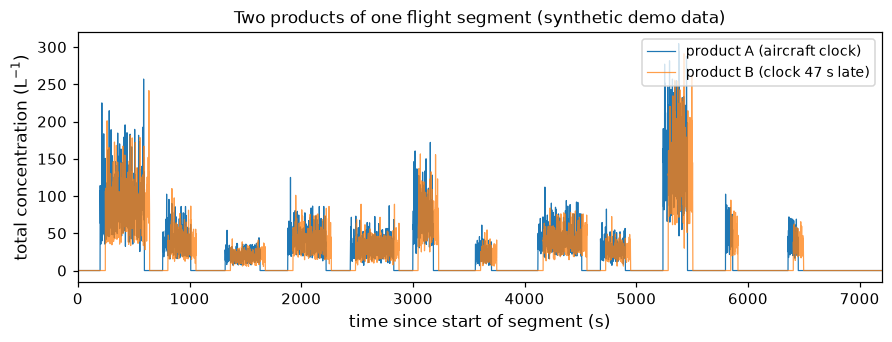

In [3]:
import tempfile
import matplotlib.pyplot as plt
import xarray as xr

with tempfile.TemporaryDirectory() as tmp_dir:
    for name, series in ("product_a", a), ("product_b", b):
        xr.Dataset({"total_concentration": (("time",), series, {"units": "L-1"})},
                   coords={"time": np.arange(series.size)}).to_netcdf(f"{tmp_dir}/{name}.nc")
    with xr.open_dataset(f"{tmp_dir}/product_a.nc") as ds_a:
        ds_a = ds_a.load()
    with xr.open_dataset(f"{tmp_dir}/product_b.nc") as ds_b:
        ds_b = ds_b.load()
print(ds_a)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "legend.fontsize": 9})
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.plot(ds_a["time"], ds_a["total_concentration"], lw=0.8, label="product A (aircraft clock)")
ax.plot(ds_b["time"], ds_b["total_concentration"], lw=0.8, alpha=0.75,
        label=f"product B (clock {OFFSET} s late)")
ax.set_xlabel("time since start of segment (s)")
ax.set_ylabel("total concentration (L$^{-1}$)")
ax.set_title("Two products of one flight segment (synthetic demo data)")
ax.margins(x=0); ax.legend(loc="upper right")
plt.show()


*Figure 1. Total concentration from two synthetic products of the same two-hour segment. Product B's clock runs late, so its trace is displaced from product A's by the offset.*

In [4]:
"""2. The lag scan, in plain numpy."""


def lag_scan(a, b, max_lag=300):
    """Pearson r of a[t] against b[t + lag] for every lag in [-max_lag, max_lag].

    Returns (lags, r, best_lag). A positive best lag means b's clock runs late.
    """
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    lags = np.arange(-max_lag, max_lag + 1)
    r = np.full(lags.size, np.nan)
    for i, lag in enumerate(lags):
        x = a[max(0, -lag):a.size - max(0, lag)]
        y = b[max(0, lag):b.size - max(0, -lag)]
        if x.std() > 0 and y.std() > 0:
            r[i] = np.corrcoef(x, y)[0, 1]
    return lags, r, int(lags[np.nanargmax(r)])


ref = flag.astype(float)
scans = {
    "A against B": lag_scan(a, b),
    "reference flag against A": lag_scan(ref, a),
    "reference flag against B": lag_scan(ref, b),
}
for name, (lags, r, best) in scans.items():
    print(f"{name:26s}: best lag {best:+4d} s, r = {np.nanmax(r):.3f} (r at lag 0 = {r[lags == 0][0]:.3f})")

assert scans["A against B"][2] == OFFSET                 # the injected offset is recovered
assert abs(scans["reference flag against A"][2]) <= 2    # A sits on aircraft time
assert abs(scans["reference flag against B"][2] - OFFSET) <= 2  # B is late; the flag's edges
                                                                 # are jittered by up to 2 s

A against B               : best lag  +47 s, r = 0.991 (r at lag 0 = 0.621)
reference flag against A  : best lag   +1 s, r = 0.690 (r at lag 0 = 0.690)
reference flag against B  : best lag  +48 s, r = 0.692 (r at lag 0 = 0.469)


This cell plots the three correlation curves from the lag scan. Each curve peaks at the lag that best lines up its two series, and the shaded band marks lags of 10 s or less.

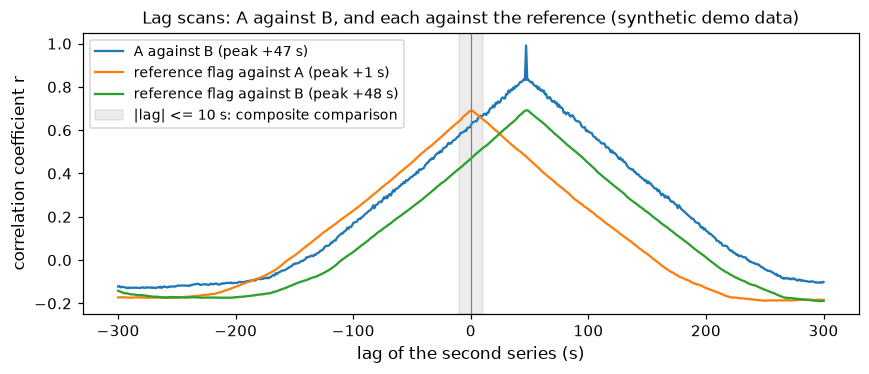

In [5]:
"""The three correlation curves: one peak each, B's displaced by the offset."""
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
for name, (lags, r, best) in scans.items():
    ax.plot(lags, r, label=f"{name} (peak {best:+d} s)")
ax.axvline(0, color="grey", lw=0.8)
ax.axvspan(-10, 10, color="grey", alpha=0.15, label="|lag| <= 10 s: composite comparison")
ax.set_xlabel("lag of the second series (s)")
ax.set_ylabel("correlation coefficient r")
ax.set_title("Lag scans: A against B, and each against the reference (synthetic demo data)")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

*Figure 2. Correlation against lag for each pair. A against B peaks at the injected offset; the shaded band is the range of lags (10 s or less) at which products are compared as leg composites instead.*

## 2b. The same scan, leg by leg

One whole-series peak could come from a single leg that dominates the correlation. Scan each cloud
leg on its own instead: a leg is a run of at least 60 s where product A's 1 Hz total concentration
is at or above a threshold, padded by 120 s each side so a shifted copy of the leg stays inside the
window, and each leg is scanned over ±90 s. **Independent legs agreeing on the same lag is the
evidence that it is a clock offset**, not a feature of one leg.

In [6]:
"""2b. A per-leg lag scan: legs from A's total concentration, each scanned over +-90 s."""
CONC_THRESHOLD = 1.0       # per litre: at or above this, a second counts as in cloud
MIN_LEG_S, PAD_S, LEG_MAX_LAG = 60, 120, 90

above = a >= CONC_THRESHOLD
run_edges = np.flatnonzero(np.diff(np.r_[0, above.astype(int), 0]))
conc_legs = [(s, e) for s, e in zip(run_edges[::2], run_edges[1::2]) if e - s >= MIN_LEG_S]


def leg_lag_scan(x, y, s, e, max_lag=LEG_MAX_LAG, pad=PAD_S):
    """Pearson r of x over the padded leg [s - pad, e + pad) against y shifted by each lag."""
    w0, w1 = max(0, s - pad), min(x.size, e + pad)
    seg_x = x[w0:w1]
    lags = np.arange(-max_lag, max_lag + 1)
    r = np.full(lags.size, np.nan)
    for i, lag in enumerate(lags):
        lo, hi = w0 + lag, w1 + lag
        if lo >= 0 and hi <= y.size and y[lo:hi].std() > 0:
            r[i] = np.corrcoef(seg_x, y[lo:hi])[0, 1]
    return int(lags[np.nanargmax(r)]), float(np.nanmax(r))


leg_best = []
for s, e in conc_legs:
    lag_leg, r_leg = leg_lag_scan(a, b, s, e)
    leg_best.append(lag_leg)
    print(f"leg {s:5d}-{e:5d} s ({e - s:3d} s): best lag {lag_leg:+3d} s, r = {r_leg:.3f}")
print()
print(f"{len(conc_legs)} legs; {sum(lag == OFFSET for lag in leg_best)} agree on {OFFSET:+d} s")
assert len(conc_legs) >= 6
assert np.median(leg_best) == OFFSET

leg   200-  596 s (396 s): best lag +47 s, r = 0.990
leg   760- 1011 s (251 s): best lag +47 s, r = 0.978
leg  1320- 1632 s (312 s): best lag +47 s, r = 0.958
leg  1880- 2223 s (343 s): best lag +47 s, r = 0.976
leg  2440- 2829 s (389 s): best lag +47 s, r = 0.965
leg  3000- 3184 s (184 s): best lag +47 s, r = 0.991
leg  3560- 3704 s (144 s): best lag +47 s, r = 0.968
leg  4120- 4512 s (392 s): best lag +47 s, r = 0.978
leg  4680- 4902 s (222 s): best lag +47 s, r = 0.966
leg  5240- 5459 s (219 s): best lag +47 s, r = 0.993
leg  5800- 5864 s ( 64 s): best lag +47 s, r = 0.990
leg  6360- 6451 s ( 91 s): best lag +47 s, r = 0.984

12 legs; 12 agree on +47 s


## 3. What the offset does to the comparison, and what correcting it gives back

The ratio below is B over A on the seconds the reference flag calls cloud. Uncorrected, each leg's
first 47 s of B are still clear air and B's last 47 s of cloud fall outside the flag, so the ratio
is biased low and the 1 Hz correlation is poor. Shifting B by the best lag restores both.

In [7]:
"""Before and after the correction."""
best = scans["A against B"][2]
b_corrected = np.zeros_like(b)
b_corrected[:b.size - best] = b[best:]                  # subtract `best` s from B's timestamps

for label, bb in (("as delivered", b), (f"B shifted by -{best} s", b_corrected)):
    r0 = np.corrcoef(a[flag], bb[flag])[0, 1]
    ratio = bb[flag].mean() / a[flag].mean()
    print(f"{label:22s}: 1 Hz r in cloud = {r0:.3f}; in-cloud mean ratio B/A = {ratio:.3f}")
print(f"{'injected ratio':22s}: {0.9:.3f}")

as delivered          : 1 Hz r in cloud = 0.555; in-cloud mean ratio B/A = 0.732
B shifted by -47 s    : 1 Hz r in cloud = 0.984; in-cloud mean ratio B/A = 0.900
injected ratio        : 0.900


## 4. A small lag: compare cloud-leg composites

A best lag of a few seconds is not worth a correction, and correcting it would only fit noise — but
it still spoils a second-by-second comparison at every leg edge. The answer is to stop comparing
seconds: average each product over each cloud leg, as the independent flag defines the legs, and
compare those composites.

In [8]:
"""Product C: the same 90 % processing with a 4 s clock offset, and the decision rule."""
SMALL_OFFSET = 4
c = np.roll(b_aircraft_time, SMALL_OFFSET)
c[:SMALL_OFFSET] = 0.0


def timing_verdict(best_lag, limit=10):
    if abs(best_lag) <= limit:
        return "compare as cloud-leg composites"
    return "systematic timing issue: flag it and correct it before quoting any ratio"


lag_c = lag_scan(a, c)[2]
print(f"A against C: best lag {lag_c:+d} s -> {timing_verdict(lag_c)}")
print(f"A against B: best lag {best:+d} s -> {timing_verdict(best)}")
assert lag_c == SMALL_OFFSET

# Legs from the reference flag: runs of consecutive in-cloud seconds.
edges = np.flatnonzero(np.diff(np.r_[0, flag.astype(int), 0]))
legs = list(zip(edges[::2], edges[1::2]))
leg_a = np.array([a[s:e].mean() for s, e in legs])
leg_c = np.array([c[s:e].mean() for s, e in legs])

per_second = c[flag] / np.where(a[flag] > 0, a[flag], np.nan)
print(f"\n{len(legs)} legs from the reference flag")
print(f"per-second ratio C/A in cloud : median {np.nanmedian(per_second):.3f}, "
      f"5-95 % range {np.nanpercentile(per_second, 5):.2f}-{np.nanpercentile(per_second, 95):.2f}")
print(f"leg-composite ratio C/A       : median {np.median(leg_c / leg_a):.3f}, "
      f"range {np.min(leg_c / leg_a):.3f}-{np.max(leg_c / leg_a):.3f}")

A against C: best lag +4 s -> compare as cloud-leg composites
A against B: best lag +47 s -> systematic timing issue: flag it and correct it before quoting any ratio

12 legs from the reference flag
per-second ratio C/A in cloud : median 0.893, 5-95 % range 0.35-2.15
leg-composite ratio C/A       : median 0.896, range 0.835-0.914


## 4b. Drift and steps: scan in windows

One whole-flight scan gives one number, and assumes the offset is constant. Repeat the scan in
windows (here 1200 s, stepped by 600 s) and read the pattern:

| Window lags | What it means | What to do |
|---|---|---|
| the same in every window | one fixed time base (a clock set wrong, or a time assignment made in processing) | shift the whole flight by it |
| creeping by a second or two over hours | clock-rate drift | nothing above the 10 s rule; note it |
| a jump between windows, often at a gap in the data | a step: the clock was reset or a block of records was re-stamped | correct each side of the step separately, never by one flight-wide shift |

Product D below carries the 47 s offset for the first hour and 120 s after it.

In [9]:
"""Product D: a clock step at t = 3600 s, found by a windowed lag scan."""
STEP_AT, LATE_BEFORE, LATE_AFTER = 3600, 47, 120
d = np.zeros(N_SECONDS)
d[LATE_BEFORE:STEP_AT] = b_aircraft_time[:STEP_AT - LATE_BEFORE]
d[STEP_AT:] = b_aircraft_time[STEP_AT - LATE_AFTER:N_SECONDS - LATE_AFTER]

WINDOW, STRIDE = 1200, 600
window_lags = []
for w0 in range(0, N_SECONDS - WINDOW - 200 + 1, STRIDE):   # whole window shiftable by +-200 s
    seg_a = a[w0:w0 + WINDOW]
    if seg_a.std() == 0:
        continue
    # Correlate this window of A against D shifted by each lag in +-200 s.
    lags, r = np.arange(-200, 201), []
    for lag in lags:
        lo, hi = w0 + lag, w0 + lag + WINDOW
        seg_d = d[lo:hi] if 0 <= lo and hi <= N_SECONDS else None
        r.append(np.corrcoef(seg_a, seg_d)[0, 1] if seg_d is not None and seg_d.std() > 0 else np.nan)
    r = np.array(r)
    if np.all(np.isnan(r)):
        continue
    best_w = int(lags[np.nanargmax(r)])
    window_lags.append((w0, best_w, np.nanmax(r)))
    print(f"window {w0:5d}-{w0 + WINDOW:5d} s: best lag {best_w:+4d} s (r = {np.nanmax(r):.2f})")

whole = lag_scan(a, d, max_lag=200)[2]
print(f"\nwhole-flight scan: {whole:+d} s -- one number that is right for neither half")
early = [lag for w0, lag, _ in window_lags if w0 + WINDOW <= STEP_AT]
late = [lag for w0, lag, _ in window_lags if w0 >= STEP_AT]
assert early and all(lag == LATE_BEFORE for lag in early)
assert late and all(lag == LATE_AFTER for lag in late)

window     0- 1200 s: best lag  +47 s (r = 0.99)
window   600- 1800 s: best lag  +47 s (r = 0.98)
window  1200- 2400 s: best lag  +47 s (r = 0.98)
window  1800- 3000 s: best lag  +47 s (r = 0.97)
window  2400- 3600 s: best lag  +47 s (r = 0.98)
window  3000- 4200 s: best lag  +47 s (r = 0.87)
window  3600- 4800 s: best lag +120 s (r = 0.98)
window  4200- 5400 s: best lag +120 s (r = 0.99)
window  4800- 6000 s: best lag +120 s (r = 0.99)
window  5400- 6600 s: best lag +120 s (r = 0.99)

whole-flight scan: +120 s -- one number that is right for neither half


## 4c. A mask on the late product's clock moves with that product

**Shift every flag, mask and leg list made on a product's clock together with the product.** A mask selects seconds, so a mask on one clock and data on another select the wrong seconds, and nothing in either file says so.

Below, B is 90 s late and carries an in-cloud mask made on its own clock, on legs of 60-200 s. Three ways to pair B with A:

- **nothing shifted**: the mask misses A's cloud, and the median leg ratio is badly wrong;
- **B shifted, mask not**: short legs are lost and the ratio can still look right, because both products are misplaced alike, so it is no check;
- **B and its mask shifted together**: every leg, and the injected ratio.

**The check for your own data** is the last two numbers on each line: the share of each product's non-zero seconds inside the mask. On a shared clock it is high (0.95 here); a mask on another clock gives a clearly lower share. Run it before and after any shift.

In [10]:
"""4c. An in-cloud mask that lives on the late product's clock, and why it must move with it."""
rng_m = np.random.default_rng(20261003)
LAG = 90                                                   # B's clock runs 90 s late
truth_m = np.zeros(N_SECONDS)
cloud_m = np.zeros(N_SECONDS, dtype=bool)                  # cloud on aircraft time
for start in np.arange(300, N_SECONDS - 500, 480)[:14]:    # fourteen short legs of 60-200 s
    length = int(rng_m.integers(60, 200))
    truth_m[start:start + length] = (rng_m.lognormal(np.log(50.0), 0.6)
                                     * rng_m.lognormal(0.0, 0.35, length))
    cloud_m[start:start + length] = True
HAZE = 0.01                                                # sparse clear-air counts, per litre
a_m = rng_m.poisson((truth_m + HAZE) * SAMPLE_VOLUME_L) / SAMPLE_VOLUME_L
b_m = np.zeros(N_SECONDS)                                  # B: 90 % of A, LAG s late
b_m[LAG:] = (rng_m.poisson((0.9 * truth_m + HAZE) * SAMPLE_VOLUME_L) / SAMPLE_VOLUME_L)[:-LAG]
mask_b = np.zeros(N_SECONDS, dtype=bool)                   # the in-cloud flag shipped with B,
mask_b[LAG:] = cloud_m[:-LAG]                              # derived on B's clock


def to_aircraft_time(x, lag):
    """Subtract `lag` s from a series' timestamps (the shift of section 3)."""
    out = np.zeros_like(x)
    out[:x.size - lag] = x[lag:]
    return out


def leg_ratios(num, den, mask):
    """Leg-mean ratio num/den on each run of the mask; legs with an empty side are counted apart."""
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(int), 0]))
    ratios, empty = [], 0
    for s, e in zip(edges[::2], edges[1::2]):
        n, d = num[s:e].mean(), den[s:e].mean()
        if n > 0 and d > 0:
            ratios.append(n / d)
        else:
            empty += 1
    return np.array(ratios), empty


def in_mask_fraction(x, mask):
    """The check: the share of a product's own non-zero seconds that the mask calls cloud."""
    return (mask & (x > 0)).sum() / (x > 0).sum()


cases = {
    "nothing shifted": (b_m, mask_b),
    "B shifted, mask not": (to_aircraft_time(b_m, LAG), mask_b),
    "B and its mask shifted": (to_aircraft_time(b_m, LAG), to_aircraft_time(mask_b, LAG)),
}
results = {}
for name, (bb, mm) in cases.items():
    ratios, empty = leg_ratios(bb, a_m, mm)
    results[name] = (np.median(ratios) if ratios.size else np.nan, empty,
                     in_mask_fraction(a_m, mm), in_mask_fraction(bb, mm))
    med, empty, fa, fb = results[name]
    spread = f"{ratios.min():.2f}-{ratios.max():.2f}" if ratios.size else "none"
    print(f"{name:23s}: median leg ratio B/A {med:6.3f} (range {spread}) on {ratios.size:2d} legs, "
          f"{empty} with an empty side; non-zero seconds in the mask: A {fa:.2f}, B {fb:.2f}")
print(f"{'injected ratio':23s}: {0.9:.3f}")

assert abs(results["nothing shifted"][0] - 0.9) > 0.5          # badly wrong
assert results["B shifted, mask not"][1] > 0                   # legs lost ...
assert max(results["B shifted, mask not"][2:]) < 0.5           # ... and the wrong seconds kept
assert abs(results["B and its mask shifted"][0] - 0.9) < 0.05   # recovered
assert results["B and its mask shifted"][1] == 0
assert min(results["B and its mask shifted"][2:]) > 0.9

nothing shifted        : median leg ratio B/A  2.176 (range 1.66-3436.67) on 12 legs, 2 with an empty side; non-zero seconds in the mask: A 0.35, B 0.95
B shifted, mask not    : median leg ratio B/A  0.892 (range 0.86-1.00) on 11 legs, 3 with an empty side; non-zero seconds in the mask: A 0.35, B 0.35
B and its mask shifted : median leg ratio B/A  0.903 (range 0.89-0.92) on 14 legs, 0 with an empty side; non-zero seconds in the mask: A 0.95, B 0.95
injected ratio         : 0.900


## 5. Doing this on your own products

1. Put both products' **1 Hz total concentration** on one time axis (a size-distribution file's
   per-second total, or the sum over its used bins), with empty seconds as zero, not missing.
2. Find an **independent reference on aircraft time** — a cloud flag, liquid water content or
   droplet concentration from another instrument — and put it on the same axis.
3. Run `lag_scan` for A against B, and for the reference against each product. Widen `max_lag` if
   a peak sits at the window's edge.
4. Apply the rule: **≤ 10 s**, compare cloud-leg composites; **> 10 s**, record the offset, shift
   the late product's time axis by it **and every mask made on its clock with it** (section 4c),
   re-run the scan to confirm a peak at 0, and only then quote a
   ratio. The reference scans say which product to shift.
5. Before applying a whole-flight shift, **scan in windows** (section 4b): one constant lag is a
   time-base offset; a jump is a step, corrected on each side separately.
6. **Keep the evidence beside the correction**: the shift in seconds, the reference it was measured
   against, the peak r, the window lags and the date, written next to the shifted output, so a
   reader can re-derive it and the unshifted product is never replaced.

A flat or double-peaked curve is a finding too: it means the series share too little cloud for the
scan to decide, and no offset should be applied on its strength.

In [11]:
"""5. Your own products: change the paths and variable names here; nothing runs until both files exist."""
PRODUCT_A = "path/to/product_a.nc"     # the product you trust to be on aircraft time
PRODUCT_B = "path/to/product_b.nc"     # the product whose clock you are checking
TIME_VAR = "time"                      # seconds, the same epoch in both files
CONC_VAR = "total_concentration"       # 1 Hz total concentration, or sum the used bins yourself
MAX_LAG = 300                          # widen if the peak sits at the edge of the scan
LIMIT_S = 10                           # the <= 10 s / > 10 s rule

if Path(PRODUCT_A).exists() and Path(PRODUCT_B).exists():
    import netCDF4

    def one_hz(path):
        with netCDF4.Dataset(path) as ds:
            t = np.round(np.asarray(ds[TIME_VAR][:], dtype=float)).astype(int)
            conc = np.ma.filled(ds[CONC_VAR][:].astype(float), 0.0)
        return t, conc

    t_a, conc_a = one_hz(PRODUCT_A)
    t_b, conc_b = one_hz(PRODUCT_B)
    t0, t1 = min(t_a.min(), t_b.min()), max(t_a.max(), t_b.max()) + 1
    series_a, series_b = np.zeros(t1 - t0), np.zeros(t1 - t0)   # empty seconds are zero
    series_a[t_a - t0] = conc_a
    series_b[t_b - t0] = conc_b
    lags_own, r_own, best_own = lag_scan(series_a, series_b, max_lag=MAX_LAG)
    print(f"A against B: best lag {best_own:+d} s, r = {np.nanmax(r_own):.3f} -> "
          f"{timing_verdict(best_own, limit=LIMIT_S)}")
else:
    print("Set PRODUCT_A and PRODUCT_B to two existing files to run the scan on your own products.")

Set PRODUCT_A and PRODUCT_B to two existing files to run the scan on your own products.


---

## Is the probe clock on the aircraft's clock?

**A size distribution is built per second of the aircraft's UTC time axis (the 1-Hz airspeed record). If the particle times are still on the probe's own clock, almost no particle lands on that axis and every second comes out empty**, with no error raised. The check: measure the offset between the record times and the particle times, accept it only if shifting by it puts nearly every particle on the axis, then bin. Worked on fixed-seed synthetic data.

## 1. A synthetic flight segment on two clocks

In [12]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(31)
axis = 43200 + np.arange(600)            # 1-Hz UTC seconds of the airspeed record (12:00-12:10)
OFFSET_TRUE = 1817                        # probe clock = UTC - 1817 s
# Particle rate: 5/s out of cloud, 150/s in a cloud between 150 s and 450 s.
rate = np.where((axis - axis[0] >= 150) & (axis - axis[0] < 450), 150.0, 5.0)
n_per_s = rng.poisson(rate)
t_utc = np.concatenate([s + np.sort(rng.random(k)) for s, k in zip(axis, n_per_s)])
t_probe = t_utc - OFFSET_TRUE             # what the particle file carries
# Each record (buffer) is stamped in UTC when written, 0-0.4 s after its particles arrived.
t_record = np.floor(t_utc + rng.uniform(0, 0.4, t_utc.size))
diam = rng.lognormal(np.log(80), 0.6, t_utc.size)   # um
edges = np.array([10, 25, 50, 100, 200, 400, 800, 1600.0])
print(f"{t_utc.size} particles, axis {axis[0]}-{axis[-1]} s, probe times {t_probe.min():.0f}-{t_probe.max():.0f} s")

46572 particles, axis 43200-43799 s, probe times 41383-41983 s


## 2. The symptom: binned on the axis, the distribution is empty

In [13]:
def bin_on_axis(t, d, axis=axis, edges=edges):
    """Counts per (axis second, size bin); particles whose second is not on the axis are dropped."""
    sec = np.floor(t).astype(int)
    on = (sec >= axis[0]) & (sec <= axis[-1])
    H, _, _ = np.histogram2d(sec[on], d[on], bins=[np.append(axis, axis[-1] + 1), edges])
    return H, on.mean()

H_raw, frac_raw = bin_on_axis(t_probe, diam)
print(f"on the axis: {100 * frac_raw:.2f} % of particles; seconds with any count: "
      f"{int((H_raw.sum(1) > 0).sum())} of {axis.size}; total counted {int(H_raw.sum())}")

on the axis: 0.00 % of particles; seconds with any count: 0 of 600; total counted 0


## 3. Measure the offset, and accept it only if it works

The offset is the mode of (record time - particle time), rounded to whole seconds. A mode is robust to the buffer delay and to a few stray records. It is accepted only if shifting by it puts at least 99 % of particles on the axis; otherwise nothing is shifted and the problem is reported.

In [14]:
ACCEPT = 0.99

def measure_offset(t_record, t_particle):
    vals, counts = np.unique(np.round(t_record - t_particle).astype(int), return_counts=True)
    return int(vals[np.argmax(counts)]), counts.max() / counts.sum()

def landed_fraction(t, axis=axis):
    sec = np.floor(t)
    return float(((sec >= axis[0]) & (sec <= axis[-1])).mean())

offset, share = measure_offset(t_record, t_probe)
frac = landed_fraction(t_probe + offset)
print(f"measured offset {offset} s (true {OFFSET_TRUE}); {100 * share:.1f} % of particles at the mode")
print(f"after the shift {100 * frac:.2f} % land on the axis -> {'ACCEPT' if frac >= ACCEPT else 'REFUSE'}")
for wrong in (0, offset - 120):
    f = landed_fraction(t_probe + wrong)
    print(f"  candidate {wrong:5d} s: {100 * f:6.2f} % on the axis -> {'ACCEPT' if f >= ACCEPT else 'REFUSE'}")

measured offset 1817 s (true 1817); 70.0 % of particles at the mode
after the shift 100.00 % land on the axis -> ACCEPT
  candidate     0 s:   0.00 % on the axis -> REFUSE
  candidate  1697 s:  98.69 % on the axis -> REFUSE


A wrong candidate is not always far off the axis: one two minutes short still lands most particles, on the wrong seconds. The acceptance test catches it here because the segment edges lose particles; the mode, not the landed fraction, is what pins the value.

## 4. The corrected binning

identical to binning the true UTC times: True


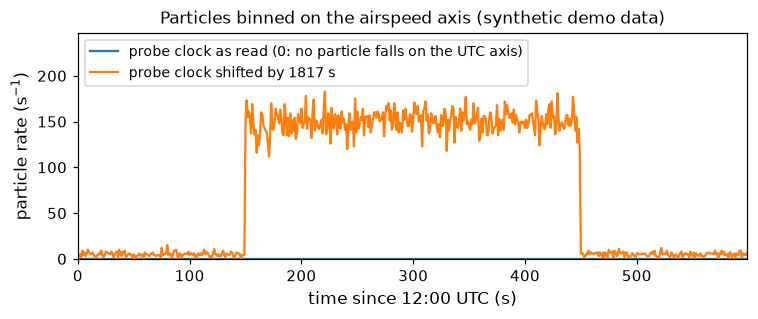

In [15]:
H_fix, frac_fix = bin_on_axis(t_probe + offset, diam)
H_true, _ = bin_on_axis(t_utc, diam)
print(f"identical to binning the true UTC times: {np.array_equal(H_fix, H_true)}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(axis - axis[0], H_raw.sum(1), label='probe clock as read (0: no particle falls on the UTC axis)')
ax.plot(axis - axis[0], H_fix.sum(1), label=f'probe clock shifted by {offset} s')
ax.set_xlabel('time since 12:00 UTC (s)'); ax.set_ylabel('particle rate (s$^{-1}$)')
ax.set_title('Particles binned on the airspeed axis (synthetic demo data)')
ax.set_ylim(0, 1.35 * H_fix.sum(1).max()); ax.margins(x=0)
ax.legend(loc='upper left', fontsize=9); fig.tight_layout(); plt.show()

*Figure 3. Particles per second on the 1-Hz UTC airspeed axis. Read on the probe's own clock, every particle time lies 1817 s before the axis, so nothing is binned and the trace sits at zero; shifted by the recovered offset, the cloud between 150 s and 450 s appears.*

## 5. What arrayprobe does

On engine 3.5, the batch driver checks for this before building the size distribution: when the particle times miss the airspeed axis, it derives the whole-second offset from the particle file itself, applies it by default, and records the applied offset in the run record (the `.call` stamp) so the output says what was done. A fixed offset can also be given explicitly (`--time-offset-s`, with its evidence). After the size-distribution stage a plausibility check measures the written product, and refuses an empty one rather than writing it silently (`--accept-implausible` keeps it, and is stamped too).

**On your own data:** set `T_RECORD`, `T_PARTICLE` and `AXIS` below to your record times, particle times and 1-Hz axis (seconds of day), and rerun.

In [16]:
T_RECORD, T_PARTICLE, AXIS = None, None, None   # e.g. arrays read with xarray

tr = T_RECORD if T_RECORD is not None else t_record
tp = T_PARTICLE if T_PARTICLE is not None else t_probe
ax_ = AXIS if AXIS is not None else axis
off, _ = measure_offset(tr, tp)
before, after = landed_fraction(tp, ax_), landed_fraction(tp + off, ax_)
print(f"on the axis as read: {100 * before:.2f} %; offset {off} s; after shift: {100 * after:.2f} % "
      f"-> {'ACCEPT' if after >= ACCEPT else 'REFUSE'}")

on the axis as read: 0.00 %; offset 1817 s; after shift: 100.00 % -> ACCEPT
